In [23]:
import pandas as pd
df = pd.read_csv('train_test_network.csv', encoding='utf-8')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes        

In [2]:
# df.head(50)

# df.normal.unique()

In [3]:
# df.type.unique()

In [24]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

SEED = 42
NUM_FEATURES = 4

In [5]:
# df.dtypes

In [6]:
# for col in df.select_dtypes(include='object').columns:
#     print(f"{col}: {df[col].nunique()} unique values")


In [25]:
categorical_cols = df.select_dtypes(include='object').columns
label_encoders = {}

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"\nColumn: {col}")
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Column: src_ip
{'13.55.50.68': 0, '172.17.0.5': 1, '172.17.0.7': 2, '172.17.0.8': 3, '192.168.1.1': 4, '192.168.1.103': 5, '192.168.1.133': 6, '192.168.1.152': 7, '192.168.1.169': 8, '192.168.1.17': 9, '192.168.1.180': 10, '192.168.1.184': 11, '192.168.1.186': 12, '192.168.1.190': 13, '192.168.1.191': 14, '192.168.1.192': 15, '192.168.1.193': 16, '192.168.1.194': 17, '192.168.1.195': 18, '192.168.1.250': 19, '192.168.1.30': 20, '192.168.1.31': 21, '192.168.1.32': 22, '192.168.1.33': 23, '192.168.1.34': 24, '192.168.1.36': 25, '192.168.1.37': 26, '192.168.1.38': 27, '192.168.1.39': 28, '192.168.1.46': 29, '192.168.1.49': 30, '192.168.1.6': 31, '192.168.1.79': 32, '199.115.158.193': 33, '203.14.129.10': 34, '220.158.215.20': 35, '2405:6e00:10ce:2c00:20c:29ff:fed2:b002': 36, '2405:6e00:10ce:2c00:20c:29ff:feee:e07a': 37, '2405:6e00:10ce:2c00:8520:4eba:6770:702a': 38, '2405:6e00:10ce:2c00:9064:17:85d2:57d4': 39, '2405:6e00:10ce:2c00:c058:dbaa:f212:a2d8': 40, 'fe80::1087:c341:7263:ead3': 41

In [8]:
# df.info()


In [26]:
feature_names = df.columns

X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution: {np.bincount(y_train)}")



Original class distribution: [ 39979 128855]


In [27]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    # Get the index of the feature with the largest absolute value in this component
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")


X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape)
print(X_test.shape)

Features Selected: 
Principal Component 1: most important feature is 'dns_rejected'
Principal Component 2: most important feature is 'http_version'
Principal Component 3: most important feature is 'ssl_established'
Principal Component 4: most important feature is 'src_pkts'
(168834, 4)
(42209, 4)


Initial Kernel Implementation: <br><br>
Accuracy: <b>87%</b>

In [ ]:
# dev = qml.device("default.qubit", wires=NUM_FEATURES)

# @qml.qnode(dev)
# def kernel_circuit(x1, x2):
#     qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
#     for wire in range(NUM_FEATURES):
#         qml.Hadamard(wires=wire)
#     qml.AngleEmbedding(x2, wires=range(NUM_FEATURES))
#     return qml.probs(wires=range(NUM_FEATURES))

# def compute_kernel_matrix(X1, X2):
#     n_samples_1, n_samples_2 = len(X1), len(X2)
#     kernel_matrix = np.zeros((n_samples_1, n_samples_2))
#     for i in range(n_samples_1):
#         if i % 10 == 0:
#             print(f"Computing row {i+1}/{n_samples_1}...")
#         for j in range(n_samples_2):
#             kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]
#     return kernel_matrix

Using a more advanced kernel circuit with Entangling Gates (CNOT and CZ) 
<br><br>
try1: 
(accuracy: 75%)

In [ ]:
# NUM_FEATURES = 4
# import pennylane as qml

# dev = qml.device("default.qubit", wires=NUM_FEATURES)

# @qml.qnode(dev)
# def kernel_circuit(x1, x2):
#     # Angle embedding for the first input
#     qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
#     # Add entangling gates (CNOT and CZ) after embedding
#     for i in range(NUM_FEATURES - 1):
#         qml.CNOT(wires=[i, i+1])
#         qml.CZ(wires=[i, i+1])
#     # Angle embedding for the second input
#     qml.AngleEmbedding(x2, wires=range(NUM_FEATURES))
#     return qml.probs(wires=range(NUM_FEATURES))

# def compute_kernel_matrix(X1, X2):
#     n_samples_1, n_samples_2 = len(X1), len(X2)
#     kernel_matrix = np.zeros((n_samples_1, n_samples_2))
#     for i in range(n_samples_1):
#         if i % 10 == 0:
#             print(f"Computing row {i+1}/{n_samples_1}...")
#         for j in range(n_samples_2):
#             kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]
#     return kernel_matrix

try 2:

In [ ]:
# NUM_FEATURES = 4
# import pennylane as qml

# dev = qml.device("default.qubit", wires=NUM_FEATURES)
# # dev = qml.device("lightning.gpu", wires=NUM_FEATURES)

# @qml.qnode(dev)
# # def zz_feature_map(x1, x2):
# def kernel_circuit(x1, x2):
#     qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
#     for i in range(NUM_FEATURES):
#         for j in range(i+1, NUM_FEATURES):
#             qml.CNOT(wires=[i, j])
#             qml.RZ(x1[i] * x1[j], wires=j)
#             qml.CNOT(wires=[i, j])
#     qml.AngleEmbedding(x2, wires=range(NUM_FEATURES))
#     return qml.probs(wires=range(NUM_FEATURES))

# def compute_kernel_matrix(X1, X2):
#     n_samples_1, n_samples_2 = len(X1), len(X2)
#     kernel_matrix = np.zeros((n_samples_1, n_samples_2))
#     for i in range(n_samples_1):
#         if i % 10 == 0:
#             print(f"Computing row {i+1}/{n_samples_1}...")
#         for j in range(n_samples_2):
#             kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]
#     return kernel_matrix

try 3:

In [ ]:
# dev = qml.device("default.qubit", wires=NUM_FEATURES)
# # Example ZZFeatureMap implementation
# @qml.qnode(dev)
# def kernel_circuit(x1, x2):
#     qml.templates.AngleEmbedding(x1, wires=range(NUM_FEATURES))
#     qml.templates.layers.StronglyEntanglingLayers(weights=np.random.rand(3, NUM_FEATURES, 3), wires=range(NUM_FEATURES))
#     qml.adjoint(qml.templates.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
#     return qml.probs(wires=range(NUM_FEATURES))

# def compute_kernel_matrix(X1, X2):
#     n_samples_1, n_samples_2 = len(X1), len(X2)
#     kernel_matrix = np.zeros((n_samples_1, n_samples_2))
#     for i in range(n_samples_1):
#         if i % 10 == 0:
#             print(f"Computing row {i+1}/{n_samples_1}...")
#         for j in range(n_samples_2):
#             kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]
#     return kernel_matrix

In [15]:
X_train_300 = X_train[:1000]
X_test_100 = X_test[:200]
y_train_300 = y_train[:1000]
y_test_100 = y_test[:200]

In [16]:
# print("Starting training kernel matrix computation...")
# training_kernel = compute_kernel_matrix(X_train_300, X_train_300)

# print("Starting testing kernel matrix computation...")
# testing_kernel = compute_kernel_matrix(X_test_100, X_train_300)

# model = SVC(kernel="precomputed", C=1)
# model.fit(training_kernel, y_train_300)

# print("Making predictions on test data...")
# y_pred_qsvc = model.predict(testing_kernel)

# accuracy_qsvc = accuracy_score(y_test_100, y_pred_qsvc)
# print(f"QSVM Accuracy on Test Data: {accuracy_qsvc:.4f}")

# print("Classification Report:\n", classification_report(y_test_100, y_pred_qsvc))

# cm = confusion_matrix(y_test_100, y_pred_qsvc)
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
# plt.title("Confusion Matrix - QSVM")
# plt.xlabel("Predicted")
# plt.ylabel("True")
# plt.tight_layout()
# plt.show()

In [28]:
def create_sequential_batches(X_train, y_train, X_test, y_test, train_batch_size=300, test_batch_size=100):
    train_batches = []
    test_batches = []
    num_batches = min(len(X_train) // train_batch_size, len(X_test) // test_batch_size)
    for i in range(num_batches):
        train_start = i * train_batch_size
        train_end = train_start + train_batch_size
        test_start = i * test_batch_size
        test_end = test_start + test_batch_size
        train_batches.append((X_train[train_start:train_end], y_train[train_start:train_end]))
        test_batches.append((X_test[test_start:test_end], y_test[test_start:test_end]))
    return train_batches, test_batches

# Usage:
train_batches, test_batches = create_sequential_batches(X_train, y_train, X_test, y_test)

print("Train Batches:")
for idx, (Xb, yb) in enumerate(train_batches):
    print(f"  Batch {idx+1}: {len(Xb)} samples")

print(len(train_batches))

print("\nTest Batches:")
for idx, (Xb, yb) in enumerate(test_batches):
    print(f"  Batch {idx+1}: {len(Xb)} samples")

Train Batches:
  Batch 1: 300 samples
  Batch 2: 300 samples
  Batch 3: 300 samples
  Batch 4: 300 samples
  Batch 5: 300 samples
  Batch 6: 300 samples
  Batch 7: 300 samples
  Batch 8: 300 samples
  Batch 9: 300 samples
  Batch 10: 300 samples
  Batch 11: 300 samples
  Batch 12: 300 samples
  Batch 13: 300 samples
  Batch 14: 300 samples
  Batch 15: 300 samples
  Batch 16: 300 samples
  Batch 17: 300 samples
  Batch 18: 300 samples
  Batch 19: 300 samples
  Batch 20: 300 samples
  Batch 21: 300 samples
  Batch 22: 300 samples
  Batch 23: 300 samples
  Batch 24: 300 samples
  Batch 25: 300 samples
  Batch 26: 300 samples
  Batch 27: 300 samples
  Batch 28: 300 samples
  Batch 29: 300 samples
  Batch 30: 300 samples
  Batch 31: 300 samples
  Batch 32: 300 samples
  Batch 33: 300 samples
  Batch 34: 300 samples
  Batch 35: 300 samples
  Batch 36: 300 samples
  Batch 37: 300 samples
  Batch 38: 300 samples
  Batch 39: 300 samples
  Batch 40: 300 samples
  Batch 41: 300 samples
  Batch 42

In [18]:
# all_test_preds = []
# num_batches = 10

# for batch_idx, (X_batch, y_batch) in enumerate(train_batches):
#     if batch_idx >= 10:
#         break
#     print(f"Training batch {batch_idx+1}/{num_batches}...")
#     # Compute kernel matrix for this batch
#     training_kernel = np.zeros((len(X_batch), len(X_batch)))
#     for i in range(len(X_batch)):
#         for j in range(len(X_batch)):
#             training_kernel[i, j] = kernel_circuit(X_batch[i], X_batch[j])[0]
#     # Train SVC
#     model = SVC(kernel="precomputed", C=10)
#     model.fit(training_kernel, y_batch)
#     # Predict on the corresponding test batch
#     X_test_batch, y_test_batch = test_batches[batch_idx]
#     testing_kernel = np.zeros((len(X_test_batch), len(X_batch)))
#     for i in range(len(X_test_batch)):
#         for j in range(len(X_batch)):
#             testing_kernel[i, j] = kernel_circuit(X_test_batch[i], X_batch[j])[0]
#     y_pred = model.predict(testing_kernel)
#     all_test_preds.append(y_pred)

# # 3. Combine predictions using majority voting
# # Stack predictions: shape (num_batches, batch_size)
# all_test_preds = np.concatenate(all_test_preds)
# # Since test batches are sequential, we can just take the mode across batches
# # For a real ensemble, you would predict all test samples with all models   , but here we use one batch per model
# # If you want to predict all test samples with all models, adjust the code accordingly

# # For demonstration, let's combine predictions for all test samples (since each sample is only predicted once)
# y_pred_ensemble = all_test_preds

# # 4. Evaluate ensemble predictions
# accuracy = accuracy_score(y_test[:1000], y_pred_ensemble)
# print(f"Ensemble QSVM Accuracy on Test Data: {accuracy:.4f}")

# print("Classification Report:\n", classification_report(y_test[:1000], y_pred_ensemble))

# cm = confusion_matrix(y_test[:1000], y_pred_ensemble)
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
# plt.title("Confusion Matrix - Ensemble QSVM")
# plt.xlabel("Predicted")
# plt.ylabel("True")
# plt.tight_layout()
# plt.show()


🔁 Batch 1/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 2/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 3/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 4/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 5/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 6/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 7/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 8/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 9/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

🔁 Batch 10/10
🔧 Computing training kernel...
🔧 Computing testing kernel...

✅ Final Batched QSVM Accuracy: 0.9040
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.70      0.79       252
           1       0.91      0.97      0.94       748

    accuracy          

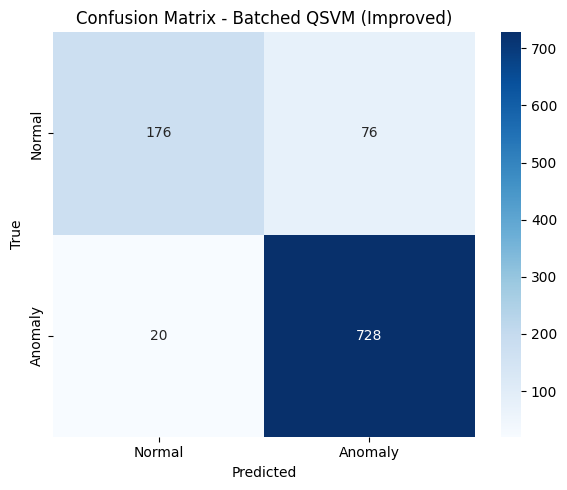

In [ ]:
SEED = 42
NUM_FEATURES = 4
TRAIN_BATCH_SIZE = 300
TEST_BATCH_SIZE = 100
NUM_BATCHES = 10

from joblib import Parallel, delayed


dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def kernel(x1, x2):
    return kernel_circuit(x1, x2)

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        for j in range(n_samples_2):
            probs = kernel_circuit(X1[i], X2[j])
            kernel_matrix[i, j] = probs[0]  # this represents the inner product now
    return kernel_matrix

# ------------------ Training on Batches ------------------
all_test_preds = []
all_test_labels = []

for batch_idx, (X_batch_train, y_batch_train) in enumerate(train_batches[:10]):
    print(f"\n🔁 Batch {batch_idx+1}/10")

    X_batch_test, y_batch_test = test_batches[batch_idx]

    # Compute kernel matrices
    print("🔧 Computing training kernel...")
    K_train = compute_kernel_matrix(X_batch_train, X_batch_train)

    print("🔧 Computing testing kernel...")
    K_test = compute_kernel_matrix(X_batch_test, X_batch_train)

    # Train QSVM
    clf = SVC(kernel="precomputed", C=1)
    clf.fit(K_train, y_batch_train)

    # Predict
    y_pred = clf.predict(K_test)
    all_test_preds.append(y_pred)
    all_test_labels.append(y_batch_test)


# ------------------ Evaluation ------------------
all_test_preds = np.concatenate(all_test_preds)
all_test_labels = np.concatenate(all_test_labels)

accuracy = accuracy_score(all_test_labels, all_test_preds)
print(f"\n✅ Final Batched QSVM Accuracy: {accuracy:.4f}")
print("Classification Report:\n", classification_report(all_test_labels, all_test_preds))

cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - Batched QSVM (Improved)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [ ]:
# # Add these imports at the top
# import os
# from joblib import dump, load
# import numpy as np

# # Create a directory to save models and test data
# model_dir = "saved_models"
# os.makedirs(model_dir, exist_ok=True)

# # Modified training loop with model saving
# all_test_preds = []
# num_batches = min(len(train_batches), 10)

# import gc  # Add this import at the top

# for batch_idx in range(num_batches):
#     X_batch, y_batch = train_batches[batch_idx]
#     print(f"\nTraining batch {batch_idx+1}/{num_batches}:")
    
#     # Compute training kernel
#     training_kernel = np.zeros((len(X_batch), len(X_batch)))
#     for i in tqdm(range(len(X_batch)), desc=f"Batch {batch_idx+1} progress", ncols=80):
#         for j in range(len(X_batch)):
#             training_kernel[i, j] = kernel_circuit(X_batch[i], X_batch[j])[0]
    
#     # Train and save model
#     model = SVC(kernel="precomputed", C=1)
#     model.fit(training_kernel, y_batch)
#     dump(model, os.path.join(model_dir, f"model_batch_{batch_idx}.joblib"))
    
#     # ======== CRITICAL MEMORY CLEANUP ========
#     # 1. Delete model and kernel matrices
#     del model, training_kernel
    
#     # 2. Clear quantum device memory
#     dev._state = None  # Clear quantum state vector
#     qml.QueuingManager.stop_recording()  # Clear operation queue
    
#     # 3. Force garbage collection
#     gc.collect()
    
#     # 4. Optional: limit memory growth for GPU
#     if 'lightning.gpu' in str(dev):
#         torch.cuda.empty_cache()
    
#     # Save training batch data (numpy arrays are manageable)
#     np.save(os.path.join(model_dir, f"X_train_batch_{batch_idx}.npy"), X_batch)
#     np.save(os.path.join(model_dir, f"y_train_batch_{batch_idx}.npy"), y_batch)
    
#     # 5. Clear input data references
#     del X_batch, y_batch


# # Save test batches and true labels
# for batch_idx, (X_test_batch, y_test_batch) in enumerate(test_batches[:num_batches]):
#     np.save(os.path.join(model_dir, f"X_test_batch_{batch_idx}.npy"), X_test_batch)
#     np.save(os.path.join(model_dir, f"y_test_batch_{batch_idx}.npy"), y_test_batch)

# print("\nAll models and data saved successfully!")


In [ ]:
# def evaluate_ensemble(model_dir, num_batches):
#     all_preds = []
#     all_true = []
    
#     for batch_idx in range(num_batches):
#         # Load model and data
#         model = load(os.path.join(model_dir, f"model_batch_{batch_idx}.joblib"))
#         X_train_batch = np.load(os.path.join(model_dir, f"X_train_batch_{batch_idx}.npy"))
#         X_test_batch = np.load(os.path.join(model_dir, f"X_test_batch_{batch_idx}.npy"))
#         y_test_batch = np.load(os.path.join(model_dir, f"y_test_batch_{batch_idx}.npy"))
        
#         # Compute testing kernel
#         testing_kernel = np.zeros((len(X_test_batch), len(X_train_batch)))
#         for i in tqdm(range(len(X_test_batch)), desc=f"Testing batch {batch_idx+1}"):
#             for j in range(len(X_train_batch)):
#                 testing_kernel[i, j] = kernel_circuit(X_test_batch[i], X_train_batch[j])[0]
        
#         # Predict and store results
#         y_pred = model.predict(testing_kernel)
#         all_preds.extend(y_pred)
#         all_true.extend(y_test_batch)
    
#     # Calculate metrics
#     accuracy = accuracy_score(all_true, all_preds)
#     print(f"\nFinal Ensemble Accuracy: {accuracy:.4f}")
#     print("\nClassification Report:")
#     print(classification_report(all_true, all_preds))
    
#     # Plot confusion matrix
#     cm = confusion_matrix(all_true, all_preds)
#     plt.figure(figsize=(6, 5))
#     sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", 
#                 xticklabels=["Normal", "Anomaly"], 
#                 yticklabels=["Normal", "Anomaly"])
#     plt.title("Ensemble Model Confusion Matrix")
#     plt.xlabel("Predicted")
#     plt.ylabel("True")
#     plt.show()

# # Usage (run this after training):
# evaluate_ensemble("saved_models", num_batches=10)


-----------------------------------------------------------------------------------------------------------------

----------------------------------------------------------------------------------------------------

In [29]:
n_layers = 6  # More layers for better expressivity

def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifier(nn.Module):
    def __init__(self, n_layers, n_qubits):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, 1)
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # No sigmoid here

Epoch 10/100, Loss: 0.4143
Epoch 20/100, Loss: 0.3299
Epoch 30/100, Loss: 0.2952
Epoch 40/100, Loss: 0.2776
Epoch 50/100, Loss: 0.2598
Epoch 60/100, Loss: 0.2452
Epoch 70/100, Loss: 0.2361
Epoch 80/100, Loss: 0.2272
Epoch 90/100, Loss: 0.2219
Epoch 100/100, Loss: 0.2106
QNN Accuracy on Test Data: 0.9200
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.68      0.79        44
           1       0.92      0.99      0.95       156

    accuracy                           0.92       200
   macro avg       0.93      0.83      0.87       200
weighted avg       0.92      0.92      0.92       200



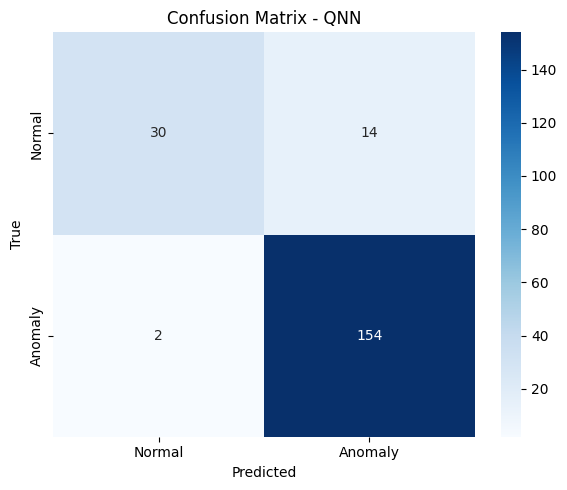

In [30]:
# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
with torch.no_grad():
    y_pred_logits = model(X_test_tensor)
    y_pred = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

accuracy_qnn = accuracy_score(y_test_100, y_pred)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, y_pred))

cm = confusion_matrix(y_test_100, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [ ]:
# print(len(y_test))